# Projeto 2 - Aprendizagem por Reforço

## Q-Learning e Sarsa no Taxi-v4

O táxi precisa buscar um passageiro e levá-lo até o destino. Neste projeto, treinamos dois agentes, um com Q-Learning e outro com Sarsa, para ver como eles aprendem essa tarefa e quantas ações precisam para terminar.

Fizemos os quatro casos pedidos no enunciado:

| Caso | Algoritmo | Ambiente de treino e teste |
| --- | --- | --- |
| 1 | Q-Learning | Determinístico, sem chuva |
| 2 | Sarsa | Determinístico, sem chuva |
| 3 | Q-Learning | Não determinístico, com chuva |
| 4 | Sarsa | Não determinístico, com chuva |

Cada caso aparece separado abaixo, com seus resultados e gráficos. Depois, juntamos os agentes nos gráficos de comparação. Também testamos as Q-tables aprendidas sem chuva no ambiente com chuva, como pede a questão 4.

O arquivo do relatório é este: `Relatorio.ipynb`, na raiz do repositório. O código está em `src`, as Q-tables em `src/data` e os resultados em `src/results`.

## Como fizemos os testes

Usamos os mesmos hiperparâmetros nos quatro casos. Foram cinco treinamentos por caso, cada um começando com uma Q-table zerada e rodando por 15.000 episódios.

Depois de cada treino, fizemos 100 testes usando a tabela aprendida. Nessa parte, o agente sempre escolhe a ação com maior valor, sem explorar e sem alterar a Q-table. Assim, cada caso tem cinco conjuntos de 100 testes, totalizando 500 episódios.

Mantivemos as mesmas seeds de teste para começar dos mesmos estados e facilitar a comparação. Como esses estados se repetem entre as cinco tabelas, os 500 episódios não são 500 condições iniciais independentes.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path.cwd()
if BASE.name == 'src':
    BASE = BASE.parent
sys.path.insert(0, str(BASE / 'src'))
from TaxiDriverGym import (ALGORITMOS, RESULTS, NOMES, criar_ambiente,
    executar_experimentos, gerar_resultados, carregar_resultados,
    resumir_avaliacoes, plotar_caso, plotar_aprendizado, plotar_acoes)

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda value: f'{value:.2f}')

# Deixe False para usar os resultados que já estão salvos.
TREINAR_NOVAMENTE = False
if TREINAR_NOVAMENTE:
    for algoritmo in ALGORITMOS:
        executar_experimentos(algoritmo)
    gerar_resultados()

config = json.loads((RESULTS / 'configuracao.json').read_text(encoding='utf-8'))
parametros = ['alpha', 'gamma', 'epsilon', 'epsilon_min', 'epsilon_dec',
              'episodios', 'seeds', 'avaliacoes_por_q_table',
              'rainy_probability', 'limite_acoes']
display(pd.DataFrame([(nome, str(config[nome])) for nome in parametros],
                     columns=['Parâmetro', 'Valor']))

,Parâmetro,Valor
0,alpha,0.1
1,gamma,0.99
2,epsilon,1.0
3,epsilon_min,0.01
4,epsilon_dec,0.995
5,episodios,15000
6,seeds,"[10, 20, 30, 40, 50]"
7,avaliacoes_por_q_table,100
8,rainy_probability,0.6
9,limite_acoes,200


### O que muda quando o táxi escorrega?

Sem chuva, o movimento é previsível. Com `is_rainy=True, rainy_probability=0.6`, o táxi tem 60% de chance de seguir a direção escolhida e 20% de ir para cada direção lateral. Se escolher direita, por exemplo, pode acabar indo para cima ou para baixo. Paredes e bordas ainda podem bloquear o movimento. As ações de buscar e deixar o passageiro não mudam com a chuva.

Mesmo se o táxi escolher direita e for para cima, atualizamos a ação direita no estado anterior, em `q_table[state, action]`. O cálculo usa a recompensa e o estado em que ele realmente chegou. É assim que a tabela aprende que escolher uma direção pode ter resultados diferentes.

O estado inclui a posição do táxi, a localização do passageiro e o destino. Por isso, a Q-table tem 500 estados e seis ações. Abaixo mostramos um exemplo tirado das transições do próprio ambiente.

In [2]:
env = criar_ambiente('nao-deterministico')
state = env.unwrapped.encode(2, 2, 0, 1)
action = 2 # Direita (leste)
transicoes = []
for prob, next_state, reward, terminated in env.unwrapped.P[state][action]:
    row, col, passenger, destination = tuple(env.unwrapped.decode(next_state))
    transicoes.append({'Ação escolhida': 'Direita', 'Probabilidade': prob,
                      'Próxima linha': row, 'Próxima coluna': col,
                      'Entrada atualizada': f'Q[{state}, {action}]'})
display(pd.DataFrame(transicoes))
env.close()

,Ação escolhida,Probabilidade,Próxima linha,Próxima coluna,Entrada atualizada
0,Direita,0.60,2,3,"Q[241, 2]"
1,Direita,0.20,1,2,"Q[241, 2]"
2,Direita,0.20,3,2,"Q[241, 2]"


### Como cada agente atualiza a tabela

O Q-Learning usa o maior valor disponível no próximo estado:

$$Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'} Q(s',a') - Q(s,a)].$$

O Sarsa usa o valor da próxima ação escolhida pela sua política, incluindo a possibilidade de explorar:

$$Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma Q(s',a') - Q(s,a)].$$

Os dois aprendem com o que aconteceu no ambiente, inclusive com os escorregões. A diferença está no valor que usam para a próxima decisão.

Quando o passageiro é entregue, o episódio termina e o valor futuro é zero. Se o táxi chega ao limite de 200 ações, o episódio também para, mas isso conta como uma tentativa que não foi concluída. Como esse limite não é um estado final da tarefa, o cálculo ainda considera o valor futuro nessa última atualização.

### Como ler os gráficos e as tabelas

O gráfico de aprendizado mostra o reward acumulado por episódio. Usamos uma média móvel de 100 episódios para enxergar melhor a evolução; os valores originais continuam nos CSVs. As linhas claras mostram cada treino e a linha mais forte mostra a média dos cinco.

A linha tracejada em reward 8 é a meta de referência do Taxi sem chuva. Entregar o passageiro rende +20, mas as ações anteriores têm penalidades, então o retorno do episódio é menor. Nos gráficos com chuva, a linha 8 fica apenas como comparação.

Contamos todas as ações: movimentos, tentativas bloqueadas, buscar e deixar o passageiro. O desvio padrão é calculado com `np.std(..., ddof=0)`, como no projeto anterior. Nos gráficos de cada caso, cada barra representa 100 testes de uma Q-table; a altura é a média e a linha preta é o desvio padrão.

Uma tentativa que chega a 200 ações sem entregar o passageiro conta como falha e entra na média geral com 200 ações. Também mostramos a taxa de sucesso e, no resumo geral, a média apenas das entregas concluídas.

In [3]:
treinos, avaliacoes = carregar_resultados()
por_execucao, resumo = resumir_avaliacoes(avaliacoes)
colunas = ['execucao', 'episodios', 'media_acoes', 'desvio_padrao_acoes',
           'sucessos', 'truncados', 'reward_medio']

def resultado(algoritmo, treino, teste):
    return resumo[(resumo['algoritmo'] == algoritmo) &
                  (resumo['ambiente_treino'] == treino) &
                  (resumo['ambiente_teste'] == teste)].iloc[0]

def mostrar_caso(algoritmo, ambiente):
    testes = por_execucao[(por_execucao['algoritmo'] == algoritmo) &
                         (por_execucao['ambiente_treino'] == ambiente) &
                         (por_execucao['ambiente_teste'] == ambiente)]
    display(testes[colunas])
    fig = plotar_caso(treinos, por_execucao, algoritmo, ambiente)
    display(fig)
    plt.close(fig)
    row = resultado(algoritmo, ambiente, ambiente)
    display(Markdown(
        f"Nos 500 testes, a média foi de **{row['media_acoes']:.2f} ações**, "
        f"com desvio padrão de **{row['desvio_padrao_acoes']:.2f}**. "
        f"O agente terminou **{int(row['sucessos'])} de {int(row['episodios'])} entregas** "
        f"({row['taxa_sucesso']:.1f}% de sucesso)."))

## Caso 1: Q-Learning no ambiente determinístico

Primeiro treinamos o Q-Learning sem chuva. Nesse ambiente, o táxi consegue aprender o caminho até o passageiro e depois até o destino sem precisar lidar com escorregões.

A curva melhora bastante no começo e depois fica mais estável. Nos testes, ele conseguiu terminar todas as entregas. A quantidade de ações varia porque o táxi e o passageiro não começam sempre no mesmo lugar.

,execucao,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio
0,1,100,12.95,2.51,100,0,8.05
2,2,100,12.95,2.51,100,0,8.05
4,3,100,12.95,2.51,100,0,8.05
6,4,100,12.95,2.51,100,0,8.05
8,5,100,12.95,2.51,100,0,8.05


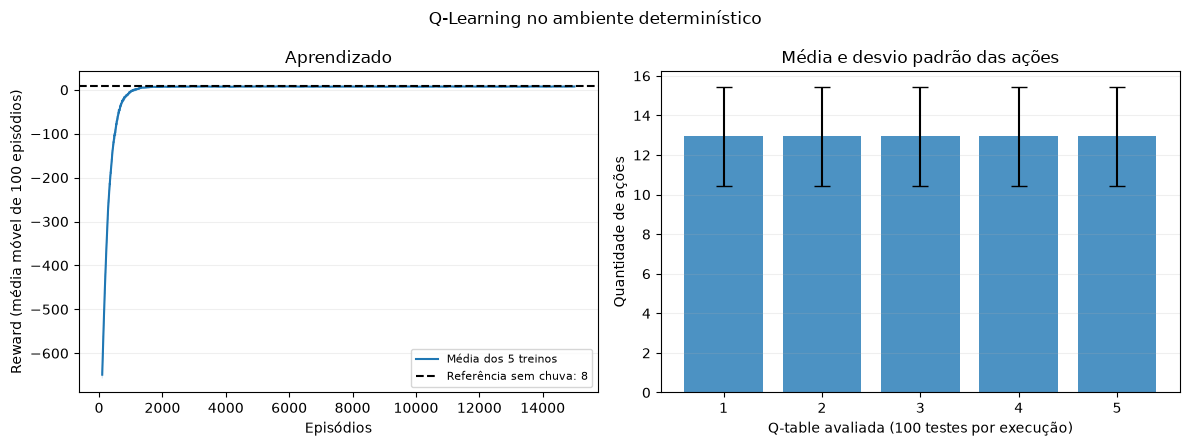

Nos 500 testes, a média foi de **12.95 ações**, com desvio padrão de **2.51**. O agente terminou **500 de 500 entregas** (100.0% de sucesso).

In [4]:
mostrar_caso('QLearning', 'deterministico')

## Caso 2: Sarsa no ambiente determinístico

Depois treinamos o Sarsa, também sem chuva e com os mesmos parâmetros. A mudança está na atualização da Q-table: ele considera a próxima ação escolhida pela sua política durante o treinamento. O resultado ficou muito próximo do Q-Learning. O Sarsa também terminou todas as entregas e usou praticamente a mesma quantidade de ações. Neste ambiente, a diferença entre os algoritmos teve pouco efeito no desempenho final.

,execucao,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio
15,1,100,12.95,2.51,100,0,8.05
17,2,100,12.99,2.44,100,0,8.01
19,3,100,12.95,2.51,100,0,8.05
21,4,100,12.95,2.51,100,0,8.05
23,5,100,12.95,2.51,100,0,8.05


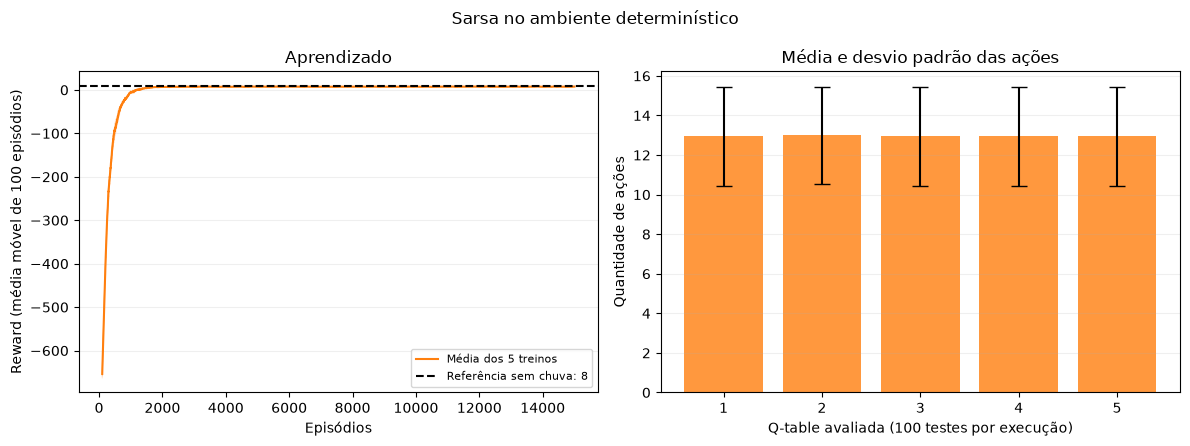

Nos 500 testes, a média foi de **12.96 ações**, com desvio padrão de **2.49**. O agente terminou **500 de 500 entregas** (100.0% de sucesso).

In [5]:
mostrar_caso('Sarsa', 'deterministico')

## Caso 3: Q-Learning no ambiente não determinístico

Aqui começamos outra Q-table e treinamos o Q-Learning com chuva. O táxi já precisa aprender levando em conta que pode escolher uma direção e acabar em outra.

Ele também terminou todas as entregas nos testes, mas precisou de mais ações do que no ambiente sem chuva. O desvio padrão aumentou: os escorregões fazem algumas viagens demorarem mais que outras, mesmo quando o agente já aprendeu a tarefa.

,execucao,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio
10,1,100,24.47,9.55,100,0,-3.47
11,2,100,24.70,8.33,100,0,-3.70
12,3,100,25.47,8.78,100,0,-4.47
13,4,100,24.35,9.05,100,0,-3.35
14,5,100,24.65,8.12,100,0,-3.65


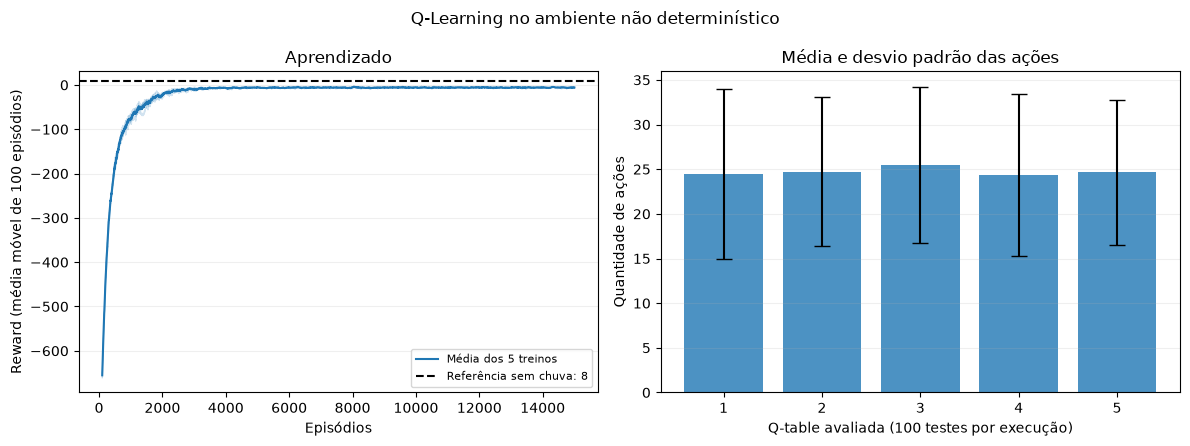

Nos 500 testes, a média foi de **24.73 ações**, com desvio padrão de **8.79**. O agente terminou **500 de 500 entregas** (100.0% de sucesso).

In [6]:
mostrar_caso('QLearning', 'nao-deterministico')

## Caso 4: Sarsa no ambiente não determinístico

Por último, treinamos o Sarsa com chuva, novamente começando a tabela do zero. Mantivemos os mesmos parâmetros usados nos outros três casos.

Assim como o Q-Learning treinado com chuva, o Sarsa terminou todas as entregas desta avaliação. As médias e os desvios ficaram bem próximos. Portanto, neste experimento, a chuva mudou mais a quantidade de ações do que a escolha entre os dois algoritmos.

,execucao,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio
25,1,100,24.48,8.63,100,0,-3.48
26,2,100,24.42,8.25,100,0,-3.42
27,3,100,24.86,8.79,100,0,-3.86
28,4,100,24.80,8.50,100,0,-3.80
29,5,100,25.55,9.40,100,0,-4.55


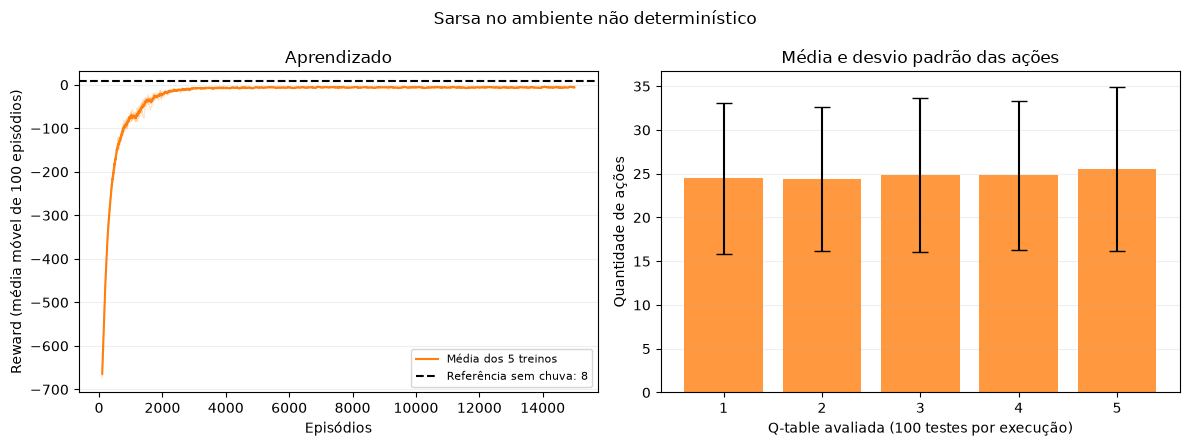

Nos 500 testes, a média foi de **24.82 ações**, com desvio padrão de **8.73**. O agente terminou **500 de 500 entregas** (100.0% de sucesso).

In [7]:
mostrar_caso('Sarsa', 'nao-deterministico')

## Comparação dos agentes: questões 1, 2 e 3

Agora colocamos os dois agentes no mesmo gráfico para comparar o aprendizado. O primeiro gráfico é do ambiente determinístico e o segundo é do não determinístico. O painel da direita amplia os últimos 5.000 episódios. A faixa em volta de cada média mostra um desvio padrão entre os cinco treinos.

Sem chuva, os dois melhoram rápido no início e depois ficam próximos. Com chuva, precisam de mais episódios para chegar perto da parte estável da curva e o reward final fica menor. Isso faz sentido porque cada viagem tende a exigir mais ações.

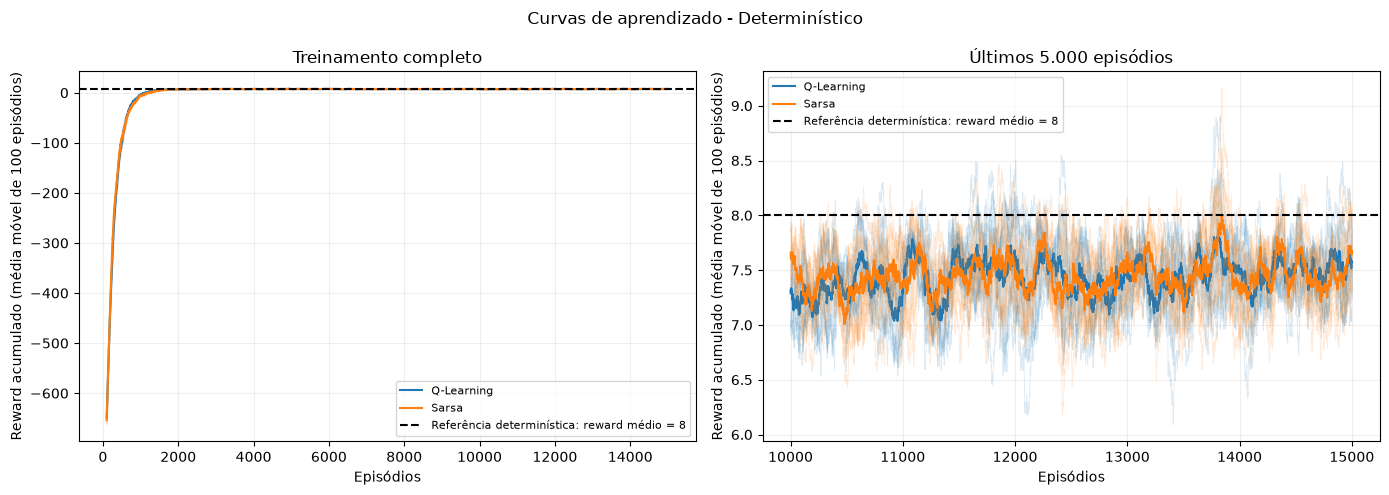

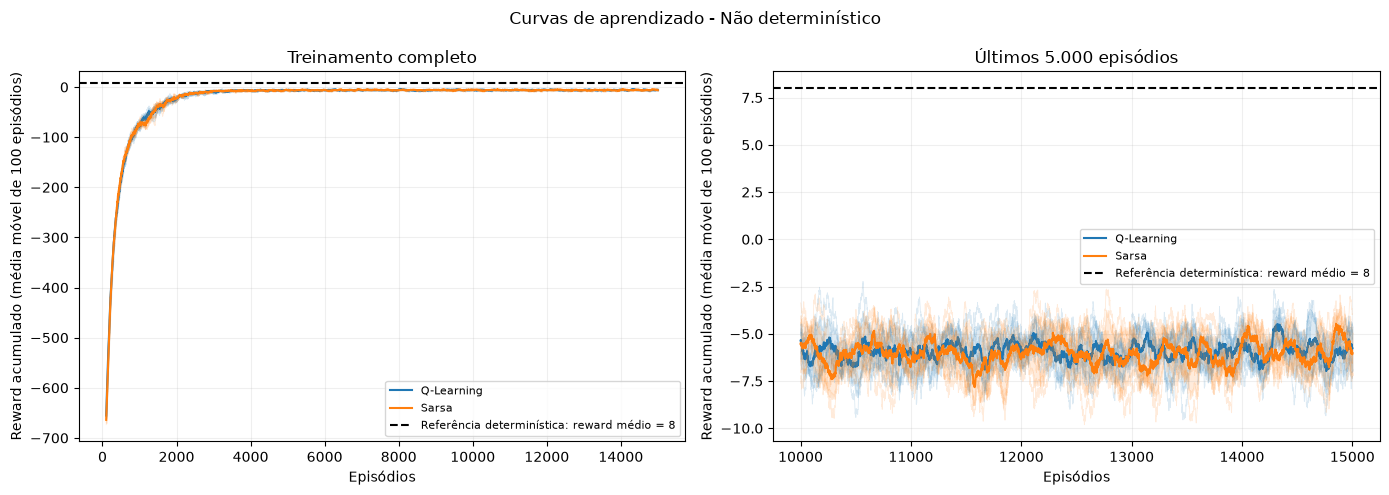

In [8]:
fig = plotar_aprendizado(treinos, 'deterministico')
display(fig)
plt.close(fig)

fig = plotar_aprendizado(treinos, 'nao-deterministico')
display(fig)
plt.close(fig)

In [9]:
# Comparação do retorno no começo e no fim dos treinamentos.
inicio = treinos[treinos['episodio'] <= 1000].groupby(
    ['algoritmo', 'ambiente_treino'])['reward'].mean().rename('reward_primeiros_1000')
fim = treinos[treinos['episodio'] > config['episodios'] - 1000].groupby(
    ['algoritmo', 'ambiente_treino'])['reward'].mean().rename('reward_ultimos_1000')
display(pd.concat([inicio, fim], axis=1).reset_index())

,algoritmo,ambiente_treino,reward_primeiros_1000,reward_ultimos_1000
0,QLearning,deterministico,-170.52,7.49
1,QLearning,nao-deterministico,-236.42,-5.90
2,Sarsa,deterministico,-167.48,7.49
3,Sarsa,nao-deterministico,-235.88,-5.87


Nos gráficos de ações abaixo, juntamos os cinco conjuntos de testes de cada agente. Cada barra representa 500 episódios, com média e desvio padrão.

Sem chuva, as médias foram 12,95 ações para Q-Learning e 12,96 para Sarsa. Com treinamento e teste na chuva, passaram para 24,73 e 24,82. Como os dois tiveram 100% de sucesso nesses quatro casos, a comparação principal aqui é quantas ações precisaram e quanto esse número variou.

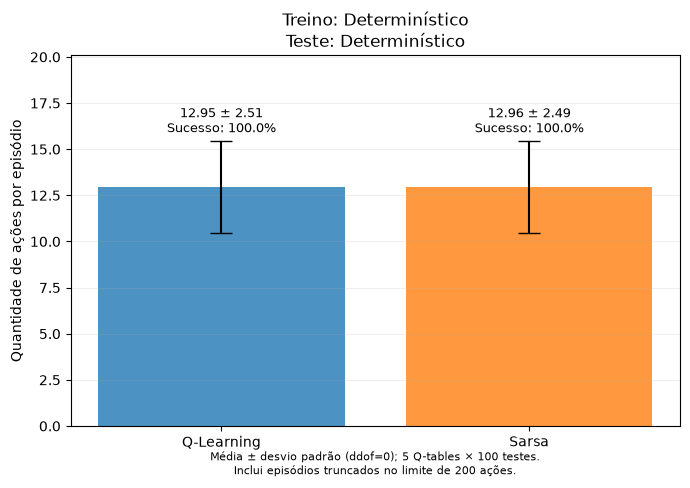

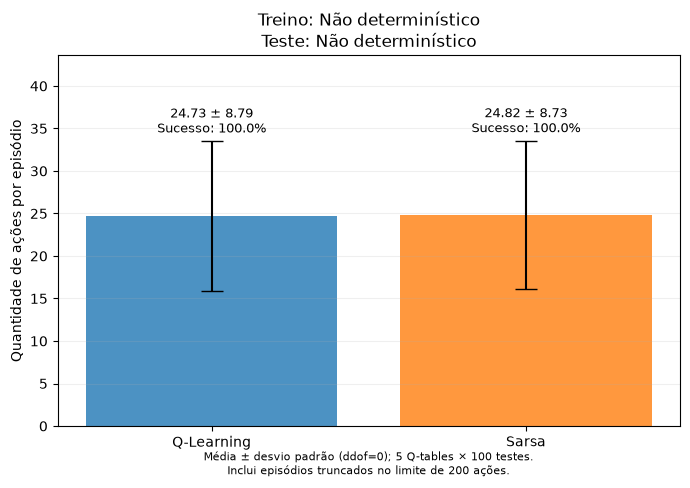

In [10]:
fig = plotar_acoes(resumo, 'deterministico', 'deterministico')
display(fig)
plt.close(fig)

fig = plotar_acoes(resumo, 'nao-deterministico', 'nao-deterministico')
display(fig)
plt.close(fig)

## Questão 4: a tabela aprendida sem chuva funciona com chuva?

Para responder, pegamos as mesmas Q-tables dos casos 1 e 2 e usamos no ambiente com chuva. Não treinamos de novo nem alteramos os valores durante os testes.

O desempenho piorou. A média subiu para 30,30 ações no Q-Learning e 30,46 no Sarsa. Além disso, 17 tentativas do Q-Learning e 16 do Sarsa chegaram ao limite de 200 ações sem terminar a entrega. A taxa de sucesso ficou em 96,6% e 96,8%.

As tabelas ainda conseguiram resolver boa parte dos testes, mas foram aprendidas em um ambiente em que os movimentos eram previsíveis. Quando o táxi escorrega, ele pode sair do caminho que tinha aprendido e precisar de mais ações para se recuperar. As falhas no limite de tempo também explicam o desvio padrão bem maior nessa etapa.

,algoritmo,execucao,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio
1,QLearning,1,100,34.59,42.44,94,6,-14.85
3,QLearning,2,100,29.56,30.90,97,3,-9.19
5,QLearning,3,100,25.01,9.31,100,0,-4.01
7,QLearning,4,100,31.10,35.32,96,4,-10.94
9,QLearning,5,100,31.26,35.51,96,4,-11.10
16,Sarsa,1,100,32.33,35.15,96,4,-12.17
18,Sarsa,2,100,34.29,39.12,95,5,-14.34
20,Sarsa,3,100,26.50,19.73,99,1,-5.71
22,Sarsa,4,100,24.74,9.84,100,0,-3.74
24,Sarsa,5,100,34.44,42.50,94,6,-14.70


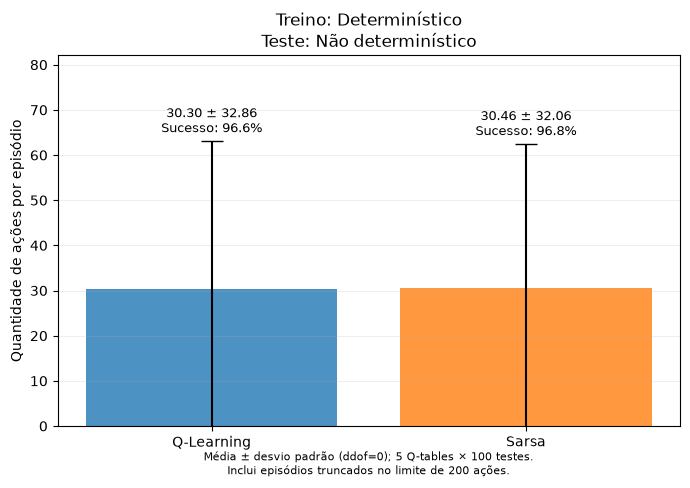

In [11]:
mascara = ((por_execucao['ambiente_treino'] == 'deterministico') &
           (por_execucao['ambiente_teste'] == 'nao-deterministico'))
display(por_execucao.loc[mascara, ['algoritmo'] + colunas])
fig = plotar_acoes(resumo, 'deterministico', 'nao-deterministico')
display(fig)
plt.close(fig)

## Questão 5: valeu a pena treinar com chuva?

Comparando o teste anterior com os casos 3 e 4, treinar com chuva ajudou. O Q-Learning passou de 30,30 para 24,73 ações em média, e o Sarsa passou de 30,46 para 24,82. Os dois voltaram a terminar todas as entregas desta avaliação e tiveram desvios menores.

Isso mostra que aprender com os escorregões fez diferença. A tabela passou a ser atualizada com resultados que realmente acontecem no ambiente com chuva. Mesmo assim, o número de ações continuou maior do que sem chuva, porque aprender uma boa política não elimina a chance de escorregar.

Entre os dois algoritmos, o Q-Learning teve uma média um pouco menor, mas os resultados ficaram próximos. O Sarsa considera a exploração na próxima ação durante o treino, enquanto o Q-Learning usa o maior valor do próximo estado. Essa diferença não fez um deles ser claramente superior nos testes que rodamos.

## Resumo dos resultados

As quatro situações de treino e teste aparecem na tabela abaixo. A linha do caso indica qual seção do relatório apresenta os detalhes.

In [12]:
quatro_casos = resumo[resumo['ambiente_treino'] == resumo['ambiente_teste']].copy()
numeros_casos = {('QLearning', 'deterministico'): 1,
                ('Sarsa', 'deterministico'): 2,
                ('QLearning', 'nao-deterministico'): 3,
                ('Sarsa', 'nao-deterministico'): 4}
quatro_casos['caso'] = [numeros_casos[(row.algoritmo, row.ambiente_treino)]
                       for row in quatro_casos.itertuples()]
quatro_casos = quatro_casos.sort_values('caso')
display(quatro_casos[['caso', 'algoritmo', 'ambiente_treino', 'episodios',
    'media_acoes', 'desvio_padrao_acoes', 'taxa_sucesso']])

# Inclui também o teste extra: tabela sem chuva usada com chuva.
display(resumo)

,caso,algoritmo,ambiente_treino,episodios,media_acoes,desvio_padrao_acoes,taxa_sucesso
0,1,QLearning,deterministico,500,12.95,2.51,100.00
3,2,Sarsa,deterministico,500,12.96,2.49,100.00
2,3,QLearning,nao-deterministico,500,24.73,8.79,100.00
5,4,Sarsa,nao-deterministico,500,24.82,8.73,100.00


,algoritmo,ambiente_treino,ambiente_teste,episodios,media_acoes,desvio_padrao_acoes,sucessos,truncados,reward_medio,media_acoes_sucessos,desvio_padrao_acoes_sucessos,taxa_sucesso
0,QLearning,deterministico,deterministico,500,12.95,2.51,500,0,8.05,12.95,2.51,100.00
1,QLearning,deterministico,nao-deterministico,500,30.30,32.86,483,17,-10.02,24.33,8.29,96.60
2,QLearning,nao-deterministico,nao-deterministico,500,24.73,8.79,500,0,-3.73,24.73,8.79,100.00
3,Sarsa,deterministico,deterministico,500,12.96,2.49,500,0,8.04,12.96,2.49,100.00
4,Sarsa,deterministico,nao-deterministico,500,30.46,32.06,484,16,-10.13,24.86,8.97,96.80
5,Sarsa,nao-deterministico,nao-deterministico,500,24.82,8.73,500,0,-3.82,24.82,8.73,100.00


## Conclusão

No nosso experimento, Q-Learning e Sarsa tiveram resultados muito parecidos. Sem chuva, os dois aprenderam a terminar as viagens usando poucas ações. Com chuva, os dois precisaram de mais ações e tiveram mais variação entre as viagens.

A maior diferença apareceu quando mudamos o ambiente sem treinar novamente. As tabelas aprendidas sem chuva ainda funcionaram em muitos testes, mas algumas tentativas não terminaram. Ao treinar diretamente com chuva, os dois agentes conseguiram lidar melhor com essa situação e terminaram todas as entregas da avaliação.

Esses resultados são dos parâmetros e das seeds que usamos. Cada caso tem cinco treinos e 100 testes por tabela. O desvio das 500 avaliações junta a variação das viagens e das tabelas aprendidas; por isso, também deixamos os resultados separados por execução.

## Onde ficaram os arquivos

- **Relatório Jupyter:** `Relatorio.ipynb`.
- **Código dos agentes:** `src/QLearning.py` e `src/Sarsa.py`.
- **Treinamentos, testes e gráficos:** `src/TaxiDriverGym.py`.
- **Q-tables:** `src/data`, com algoritmo, ambiente e execução no nome.
- **Dados e gráficos:** `src/results`.

Para abrir o notebook, siga os comandos do README. Ele já vem com os resultados salvos. Para treinar tudo de novo pelo notebook, mude `TREINAR_NOVAMENTE` para `True`. Se apenas executar as células como estão, elas carregam os CSVs existentes e refazem os gráficos.

## Referências

- [Documentação do Taxi-v4](https://gymnasium.farama.org/v1.3.0/environments/toy_text/taxi/).
- [Registro do ambiente: limite de ações e referência de reward](https://github.com/Farama-Foundation/Gymnasium/blob/v1.3.0/gymnasium/envs/__init__.py).
- [Código das transições do Taxi](https://github.com/Farama-Foundation/Gymnasium/blob/v1.3.0/gymnasium/envs/toy_text/taxi.py).